In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings("ignore")
%matplotlib inline

In [6]:
dataset = pd.read_csv("cleaned_train_data.csv")
X = dataset.drop('Price', axis=1)
y = dataset['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(4671, 11) (1168, 11)


In [7]:

cat_cols = ['Location', 'Fuel_Type', 'Transmission', 'Brand Name']
num_cols = ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats']

owner_order = [['First', 'Second', 'Third', 'Fourth & Above']]


def make_model(regressor, scale=False):

    prep = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('owner', OrdinalEncoder(categories=owner_order), ['Owner_Type']),
        ('num', StandardScaler() if scale else 'passthrough', num_cols),
    ])
    pipe = Pipeline([('prep', prep), ('model', regressor)])

    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

In [8]:

models = {
    'Linear Regression': make_model(LinearRegression(), scale=True),
    'Random Forest': make_model(RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                      max_features=0.75, n_jobs=-1, random_state=42)),
    'XGBoost': make_model(XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
                                       colsample_bytree=0.8, n_jobs=-1, random_state=42)),
    'Stacking': make_model(StackingRegressor(
        estimators=[
            ('rf', RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.75,
                                         n_jobs=-1, random_state=42)),
            ('gbdt', GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                                               subsample=0.8, random_state=42)),
            ('xgb', XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                                 colsample_bytree=0.8, n_jobs=-1, random_state=42)),
        ],
        final_estimator=Ridge(alpha=1.0), n_jobs=1)),
}


cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'})
    rows.append({'model': name,
                 'cv_r2_mean': res['test_r2'].mean(), 'cv_r2_std': res['test_r2'].std(),
                 'cv_mae_lakh': -res['test_mae'].mean()})
    print(f"{name:20s} R2 = {res['test_r2'].mean():.4f} +/- {res['test_r2'].std():.4f} | MAE = {-res['test_mae'].mean():.3f}")

cv_results = pd.DataFrame(rows).set_index('model').sort_values('cv_r2_mean', ascending=False).round(4)
display(cv_results)

Linear Regression    R2 = 0.8137 +/- 0.1279 | MAE = 1.817
Random Forest        R2 = 0.8861 +/- 0.0259 | MAE = 1.522
XGBoost              R2 = 0.9134 +/- 0.0251 | MAE = 1.233
Stacking             R2 = 0.9125 +/- 0.0257 | MAE = 1.266


,cv_r2_mean,cv_r2_std,cv_mae_lakh
model,,,
XGBoost,0.9134,0.0251,1.2327
Stacking,0.9125,0.0257,1.2655
Random Forest,0.8861,0.0259,1.5220
Linear Regression,0.8137,0.1279,1.8174


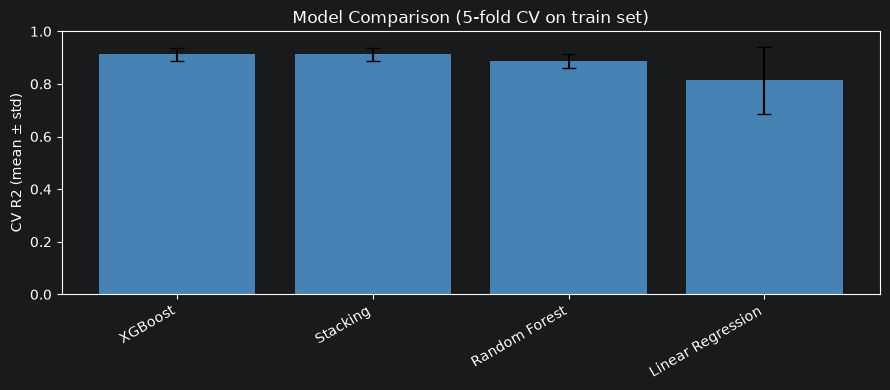

In [10]:
plt.figure(figsize=(9, 4))
plt.bar(cv_results.index, cv_results['cv_r2_mean'], yerr=cv_results['cv_r2_std'], capsize=5, color='steelblue')
plt.ylim(0, 1)
plt.ylabel('CV R2 (mean ± std)')
plt.title('Model Comparison (5-fold CV on train set)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Best model: XGBoost
Test R2  : 0.9428
Test MAE : 1.140 Lakh


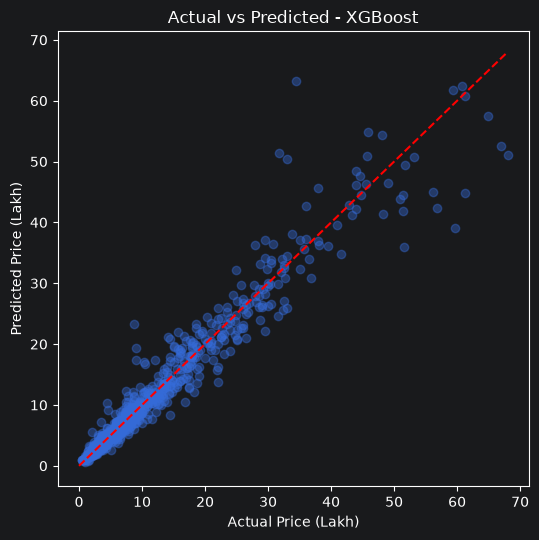

In [11]:

best_model_name = cv_results['cv_r2_mean'].idxmax()
best_model = clone(models[best_model_name]).fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(f"Best model: {best_model_name}")
print(f"Test R2  : {r2_score(y_test, y_pred):.4f}")
print(f"Test MAE : {mean_absolute_error(y_test, y_pred):.3f} Lakh")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, y_pred, alpha=0.4)
lim = [0, max(y_test.max(), y_pred.max())]
plt.plot(lim, lim, 'r--')
plt.xlabel('Actual Price (Lakh)')
plt.ylabel('Predicted Price (Lakh)')
plt.title(f'Actual vs Predicted - {best_model_name}')
plt.tight_layout()
plt.show()

In [12]:

final_model = clone(models[best_model_name]).fit(X, y)

with open('pipe.pkl', 'wb') as f:
    pickle.dump(final_model, f)
with open('train.pkl', 'wb') as f:
    pickle.dump(dataset, f)
print("Saved pipe.pkl and train.pkl")


example = pd.DataFrame([{
    'Location': 'Mumbai', 'Year': 2015, 'Kilometers_Driven': 50000, 'Fuel_Type': 'Diesel',
    'Transmission': 'Manual', 'Owner_Type': 'First', 'Mileage': 18.0, 'Engine': 1498,
    'Power': 98.6, 'Seats': 5.0, 'Brand Name': 'Hyundai'}])
print("Example prediction (Lakh):", final_model.predict(example[list(X.columns)])[0])

Saved pipe.pkl and train.pkl
Example prediction (Lakh): 6.0893245
